# Where the risk of the multi-factor strategy comes from

The multi-factor strategy of the companion repository, [brazil-equity-factors](https://github.com/pedroandion/brazil-equity-factors) (notebook `05_multi_factor_strategy`), and its three sleeves:

| Strategy | Stocks | Rule |
|---|---|---|
| Magic Formula | 20 | Return on capital, earnings yield, net debt / EBIT, low volatility and momentum, ranked together; financials and utilities excluded |
| LowVol Momentum | 10 | The least volatile stocks among the top 20% by momentum |
| Quality | 10 | Profitability and value, without the 20% weakest in leverage or growth |
| Combination | Up to 40 | The three sleeves together; a stock picked by more than one gets a larger weight |

All four are long-only, equally weighted and rebalanced on the first business day of each month, before transaction costs. This notebook regresses their returns in excess of the SELIC rate on the seven local factors, original and orthogonal, and splits their variance among the factors, as Tables 4 to 6 of the paper do for the US portfolios.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_strategies, to_monthly, BRAZIL_FACTORS,
                               BRAZIL_STRATEGIES, MONTHLY_SAMPLE)
from orthofactors.orthogonalization import orthogonalize_swl_correlation
from orthofactors.decomposition import run_ols, decompose, variance_levels, gs_order_range
from orthofactors.plotting import set_style, factor_colors, plot_decomposition_bars

set_style()
Path('results').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

## Data

Daily returns from 2010-01-05 to 2026-07-23, in excess of the SELIC rate, the same risk-free rate as the market factor. The monthly returns compound the daily excess returns, as the companion does, from February 2010 to June 2026 (197 months). The t-statistics use Newey-West errors, with 4 lags in monthly data and 5 in daily data.

In [2]:
factors_daily = load_brazil_factors()[BRAZIL_FACTORS]
strategies_daily = load_brazil_strategies()
factors = to_monthly(factors_daily).loc[MONTHLY_SAMPLE]
strategies = to_monthly(strategies_daily).loc[MONTHLY_SAMPLE]

pd.DataFrame({'Mean excess return': strategies.mean() * 12, 'Volatility': strategies.std() * np.sqrt(12),
              'Months': strategies.count()}).style.format({'Mean excess return': '{:.2%}', 'Volatility': '{:.2%}'})

,Mean excess return,Volatility,Months
Combination,5.70%,18.18%,197
Magic Formula,4.66%,17.96%,197
LowVol Momentum,7.56%,18.39%,197
Quality,3.77%,22.96%,197


## Betas and alpha

In [3]:
# Regressions on the original factors and on the factors orthogonalized on the same months
original = {s: run_ols(strategies[s], factors, hac_lags = 4) for s in BRAZIL_STRATEGIES}
orthogonal = {s: decompose(strategies[s], factors, hac_lags = 4) for s in BRAZIL_STRATEGIES}

betas = pd.DataFrame({s: pd.concat([original[s].params[BRAZIL_FACTORS], orthogonal[s][0].params[BRAZIL_FACTORS]],
                                   keys = ['β', 'β⊥']) for s in BRAZIL_STRATEGIES}).T
tstats = pd.DataFrame({s: pd.concat([original[s].tvalues[BRAZIL_FACTORS], orthogonal[s][0].tvalues[BRAZIL_FACTORS]],
                                    keys = ['β', 'β⊥']) for s in BRAZIL_STRATEGIES}).T
betas.round(2)

β                                         β⊥              \
                Mkt_RF   SMB   HML   RMW   CMA   WML   BAB Mkt_RF   SMB   HML   
Combination       0.87  0.42 -0.05  0.26  0.06  0.21  0.17   0.70  0.39  0.01   
Magic Formula     0.83  0.47 -0.11  0.21  0.03  0.23  0.18   0.66  0.41 -0.05   
LowVol Momentum   0.88  0.33  0.04  0.24  0.14  0.40  0.20   0.68  0.28  0.01   
Quality           0.90  0.36  0.05  0.37  0.05 -0.01  0.11   0.78  0.43  0.15   

                                         
                  RMW   CMA   WML   BAB  
Combination      0.20 -0.06  0.09 -0.19  
Magic Formula    0.19 -0.10  0.12 -0.17  
LowVol Momentum  0.17  0.01  0.24 -0.14  
Quality          0.24 -0.04 -0.15 -0.31

In [4]:
tstats.round(2)

β                                         β⊥              \
                Mkt_RF   SMB   HML   RMW   CMA   WML   BAB Mkt_RF   SMB   HML   
Combination      20.42  7.89 -0.64  4.73  1.08  4.52  3.34  25.19  9.59  0.21   
Magic Formula    18.18  8.32 -1.38  3.37  0.43  4.20  3.36  21.47  9.50 -1.20   
LowVol Momentum  18.76  5.15  0.48  3.54  1.92  7.57  3.42  22.80  5.95  0.24   
Quality          12.78  4.44  0.47  4.82  0.65 -0.16  1.41  15.87  6.81  2.30   

                                         
                  RMW   CMA   WML   BAB  
Combination      4.65 -1.17  2.65 -7.30  
Magic Formula    3.70 -1.76  3.25 -5.62  
LowVol Momentum  3.41  0.24  6.62 -4.89  
Quality          3.95 -0.53 -2.15 -7.76

In [5]:
# The alpha, its t-statistic and the R² are the same with both sets of factors
pd.DataFrame({s: {'Alpha per month, original': original[s].params['const'], 'Alpha per month, orthogonal': orthogonal[s][0].params['const'],
                  't, original': original[s].tvalues['const'], 't, orthogonal': orthogonal[s][0].tvalues['const'],
                  'R², original': original[s].rsquared, 'R², orthogonal': orthogonal[s][0].rsquared}
              for s in BRAZIL_STRATEGIES}).T.style.format('{:.4f}')

,"Alpha per month, original","Alpha per month, orthogonal","t, original","t, orthogonal","R², original","R², orthogonal"
Combination,0.0028,0.0028,1.7250,1.7250,0.8356,0.8356
Magic Formula,0.0019,0.0019,1.0955,1.0955,0.7857,0.7857
LowVol Momentum,0.0015,0.0015,0.7206,0.7206,0.7451,0.7451
Quality,0.0041,0.0041,1.3919,1.3919,0.7157,0.7157


The orthogonal betas differ in two places. The market beta of the Combination falls from 0.87 to 0.70, and the BAB beta changes sign, from +0.17 to −0.19, which makes it the most significant beta after the market and size (t-statistic of −7.3). BAB is short the market, so a positive BAB beta partly stands in for a lower market beta. Once the market is taken out of BAB, the strategies lean slightly against the low-beta bet. All four strategies have positive and significant betas on SMB and RMW in both versions.

The alpha is the same with both sets of factors, as Appendix A of the paper shows, and so are its t-statistic and the R². The Combination earns 0.28% a month beyond the seven factors, with a t-statistic of 1.7, not significant at 5%.

## The systematic variance, factor by factor

In [6]:
# Monthly variances in percent squared: the naive sum of (β_k σ_k)², the systematic variance and its exact split
levels = {s: variance_levels(strategies[s], factors) * 1e4 for s in BRAZIL_STRATEGIES}
pd.DataFrame({s: {'Naive sum': t.loc['sum', 'original'], 'Systematic variance': t.loc['systematic', 'original'],
                  'Orthogonal sum': t.loc['sum', 'orthogonal'], 'Idiosyncratic variance': t.loc['idiosyncratic', 'original'],
                  'Total variance': t.loc['total', 'original']} for s, t in levels.items()}).T.round(2)

,Naive sum,Systematic variance,Orthogonal sum,Idiosyncratic variance,Total variance
Combination,34.16,23.02,23.02,4.53,27.55
Magic Formula,33.00,21.13,21.13,5.76,26.89
LowVol Momentum,37.42,21.00,21.00,7.18,28.18
Quality,33.59,31.45,31.45,12.49,43.95


In [7]:
# Factor by factor for the Combination
levels['Combination'].round(2)

,original,orthogonal
Mkt_RF,27.00,17.43
SMB,3.40,2.99
HML,0.05,0.00
RMW,0.96,0.59
CMA,0.04,0.04
WML,1.33,0.22
BAB,1.38,1.75
sum,34.16,23.02
systematic,23.02,23.02
idiosyncratic,4.53,4.53


Without the orthogonalization, adding up the terms of each factor overstates the systematic risk of every strategy: by 48% for the Combination (34.2 against 23.0) and by 78% for LowVol Momentum. In the US data of the paper the naive sum was usually too small, because the main factors were positively correlated. Here the strategies have positive betas on the market and on BAB, which move against each other, so the cross term is negative and the naive sum counts risk that cancels out. With the orthogonal factors the terms add up exactly.

## Decomposed $R^2$

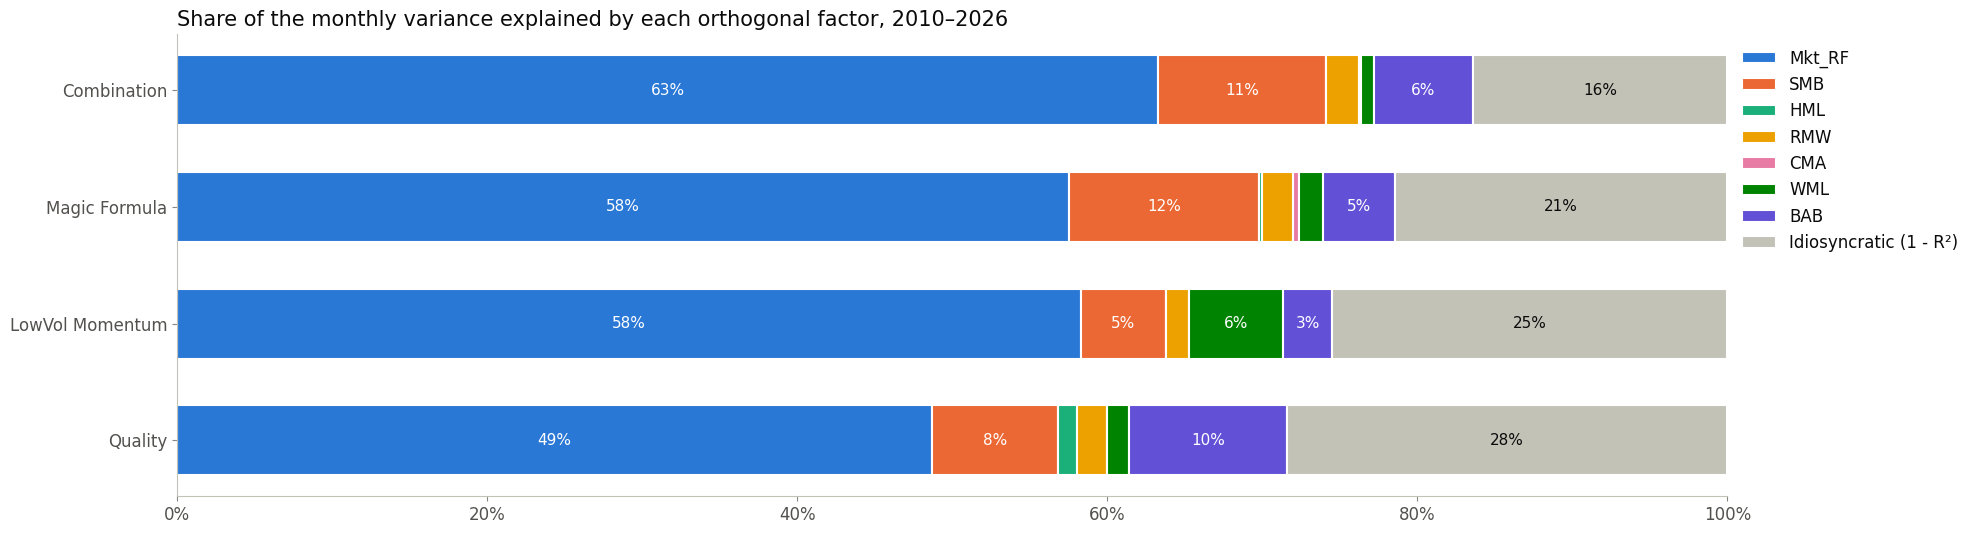

,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB,idiosyncratic
Combination,63.25%,10.86%,0.01%,2.13%,0.15%,0.81%,6.35%,16.44%
Magic Formula,57.51%,12.27%,0.21%,1.96%,0.42%,1.52%,4.68%,21.43%
LowVol Momentum,58.29%,5.46%,0.01%,1.52%,0.01%,6.05%,3.18%,25.49%
Quality,48.68%,8.14%,1.19%,1.94%,0.04%,1.40%,10.17%,28.43%


In [8]:
decomposition = pd.DataFrame({s: pd.concat([orthogonal[s][1], pd.Series({'idiosyncratic': 1 - orthogonal[s][0].rsquared})])
                              for s in BRAZIL_STRATEGIES}).T
assert np.allclose(decomposition.sum(axis = 1), 1)

fig, ax = plt.subplots(figsize = (20, 6))
plot_decomposition_bars(ax, decomposition, BRAZIL_FACTORS, 'Share of the monthly variance explained by each orthogonal factor, 2010–2026')
plt.show()

decomposition.style.format('{:.2%}')

The market explains most of the variance of every strategy, from 49% (Quality) to 63% (the Combination). Size comes second for three of them, with 5% to 12%, and BAB third, with 3% to 10%; for Quality, BAB comes second. Momentum explains 6% of LowVol Momentum and less than 2% of the others, and value, profitability and investment together explain at most 3.2% of any strategy. The idiosyncratic share is 16% for the Combination and 21% to 28% for the sleeves, so combining them diversifies away part of what is specific to each.

## What Gram-Schmidt would say

Gram-Schmidt also gives uncorrelated factors, but the answer depends on the order: the first factor keeps everything it shares with the others. The chart runs all 5,040 orders of the seven factors and shows the range of each share, with the SW/L share as a dot.

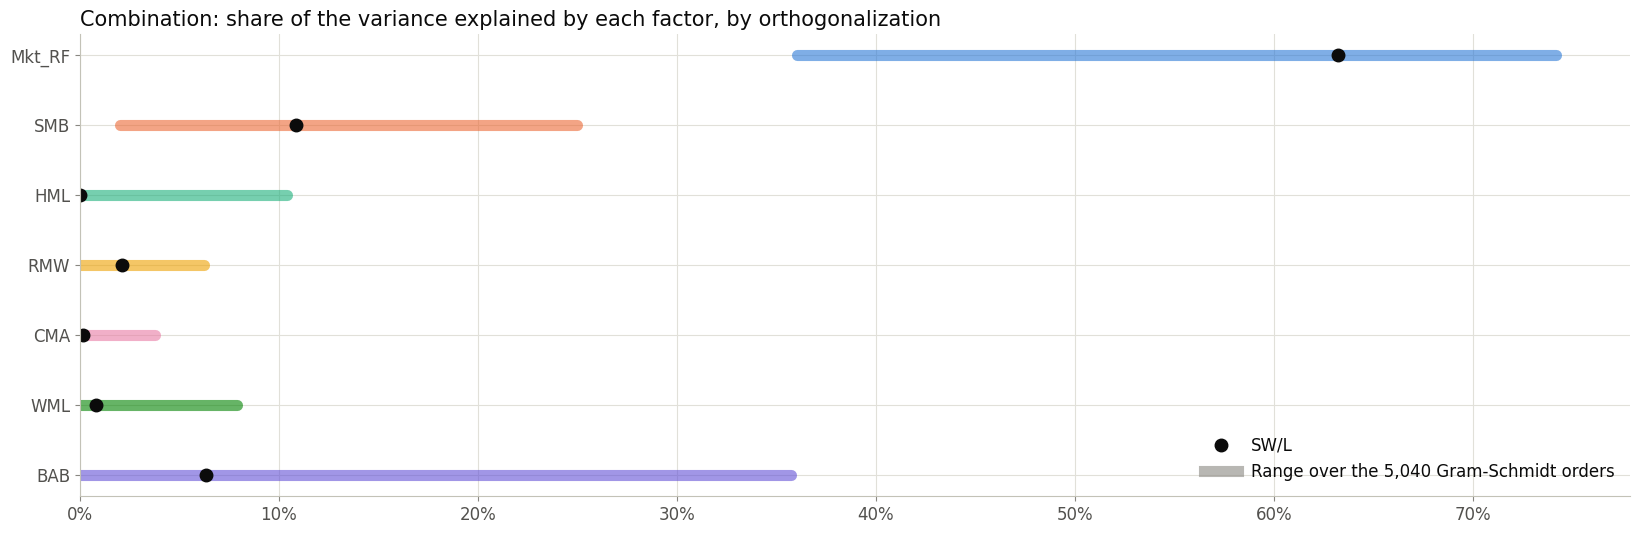

In [9]:
gs_orders = {s: gs_order_range(strategies[s], factors) for s in BRAZIL_STRATEGIES}
gs_range = pd.concat({s: pd.DataFrame({'Lowest': g.min(), 'Highest': g.max(), 'SW/L': decomposition.loc[s, BRAZIL_FACTORS]})
                      for s, g in gs_orders.items()})

fig, ax = plt.subplots(figsize = (20, 6))
combination = gs_range.loc['Combination']
for y, factor in enumerate(BRAZIL_FACTORS):
    ax.plot([combination.loc[factor, 'Lowest'], combination.loc[factor, 'Highest']], [y, y], color = colors[factor],
            linewidth = 8, solid_capstyle = 'round', alpha = 0.6)
    ax.plot(combination.loc[factor, 'SW/L'], y, 'o', color = '#0b0b0b', markersize = 9)
ax.plot([], [], 'o', color = '#0b0b0b', markersize = 9, label = 'SW/L')
ax.plot([], [], color = '#898781', linewidth = 8, alpha = 0.6, label = 'Range over the 5,040 Gram-Schmidt orders')
ax.set_yticks(range(len(BRAZIL_FACTORS)), BRAZIL_FACTORS)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, None)
ax.set_title('Combination: share of the variance explained by each factor, by orthogonalization')
ax.legend(loc = 'lower right')
plt.show()

gs_range.unstack(0).swaplevel(axis = 1).sort_index(axis = 1, level = 0, sort_remaining = False)[BRAZIL_STRATEGIES].style.format('{:.1%}')

With Gram-Schmidt the answer depends on an arbitrary choice. Depending on the order, BAB explains anything from 0% to 36% of the variance of the Combination, and the market from 36% to 74%; for Quality, BAB goes up to 43%. The SW/L shares sit inside these ranges without favoring any factor, and they do not depend on the order of the columns.

## The model without BAB

The portfolio construction project used six factors, without BAB. The same decomposition with six factors shows what BAB takes from the others.

In [10]:
six = [f for f in BRAZIL_FACTORS if f != 'BAB']
without_bab = {s: decompose(strategies[s], factors[six]) for s in BRAZIL_STRATEGIES}
comparison = pd.concat({'Seven factors': decomposition[['Mkt_RF', 'SMB', 'BAB', 'idiosyncratic']],
                        'Without BAB': pd.DataFrame({s: pd.concat([d, pd.Series({'idiosyncratic': 1 - r.rsquared})])
                                                     for s, (r, d) in without_bab.items()}).T[['Mkt_RF', 'SMB', 'idiosyncratic']]}, axis = 1)
comparison.style.format('{:.2%}', na_rep = '')

Dropping BAB costs little fit: the idiosyncratic share of the Combination rises from 16.4% to 17.7%, and that of Quality from 28.4% to 28.7%. The share of BAB goes mostly to the market, which rises from 48.7% to 55.6% for Quality. The six-factor model fits the strategies almost as well, but it credits the market with risk that the seven-factor decomposition assigns to the low-beta bet.

## Robustness

The same decomposition with daily returns, and with the correlation version of SW/L, which does not change when one factor is rescaled.

In [11]:
def decomposition_of(returns, factor_returns, **kwargs):
    rows = {}
    for s in BRAZIL_STRATEGIES:
        result, dr2 = decompose(returns[s], factor_returns, **kwargs)
        rows[s] = pd.concat([dr2, pd.Series({'idiosyncratic': 1 - result.rsquared})])
    return pd.DataFrame(rows).T

robustness = pd.concat({'Monthly': decomposition,
                        'Daily': decomposition_of(strategies_daily, factors_daily),
                        'Monthly, correlation version': decomposition_of(strategies, factors, orthogonalize = orthogonalize_swl_correlation)})
robustness.style.format('{:.2%}')

The order of the sources holds in daily data and with the correlation version. With daily returns the market explains more, 73% of the Combination, and size less, 5%, probably because small caps trade less often and react to news with a lag, which weakens their daily co-movement. The correlation version moves the shares by at most 2.4 points (BAB for Quality), so the scale of BAB, which is not levered, does not drive the results.

In [12]:
decomposition.round(4).to_csv('results/strategy_decomposition.csv')
gs_range.round(4).to_csv('results/strategy_gram_schmidt_range.csv')
robustness.round(4).to_csv('results/strategy_decomposition_robustness.csv')